In [1]:
print("Car Price Prediction Project Started!")

Car Price Prediction Project Started!


In [2]:
# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Cell 2: Load the dataset

from pathlib import Path
import pandas as pd

data_folder = Path("data")

csv_files = list(data_folder.glob("*.csv"))

if not csv_files:
    print("CSV file nahi mili. Data folder check karo.")
else:
    file_path = csv_files[0]
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("File name:", file_path.name)
    print("Rows and Columns:", df.shape)

    display(df.head())

Dataset loaded successfully!
File name: CAR DETAILS FROM CAR DEKHO.csv
Rows and Columns: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [5]:
# Step 4: Check dataset information

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Rows:
763

Statistical Summary:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [7]:
# Step 5: Data Cleaning

# Make a copy of the original data
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
text_columns = [
    "name",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Standardize categorical values
df["fuel"] = df["fuel"].str.lower().str.title()
df["seller_type"] = df["seller_type"].str.lower().str.title()
df["transmission"] = df["transmission"].str.lower().str.title()
df["owner"] = df["owner"].str.lower().str.title()

print("Data cleaning completed!")
print("Rows after removing duplicates:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum())

Data cleaning completed!
Rows after removing duplicates: 3577
Duplicate rows remaining: 0
Missing values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [8]:
# Step 6: Feature Engineering

import pandas as pd

# Calculate car age using the latest dataset year
reference_year = int(df["year"].max())

df["car_age"] = reference_year - df["year"]

# Extract brand from car name
df["brand"] = df["name"].str.split().str[0]

print("Reference year:", reference_year)
print("Brand and car age created successfully!")

display(df[["name", "year", "brand", "car_age"]].head(10))

Reference year: 2020
Brand and car age created successfully!


,name,year,brand,car_age
0,Maruti 800 AC,2007,Maruti,13
1,Maruti Wagon R LXI Minor,2007,Maruti,13
2,Hyundai Verna 1.6 SX,2012,Hyundai,8
3,Datsun RediGO T Option,2017,Datsun,3
4,Honda Amaze VX i-DTEC,2014,Honda,6
5,Maruti Alto LX BSIII,2007,Maruti,13
6,Hyundai Xcent 1.2 Kappa S,2016,Hyundai,4
7,Tata Indigo Grand Petrol,2014,Tata,6
8,Hyundai Creta 1.6 VTVT S,2015,Hyundai,5
9,Maruti Celerio Green VXI,2017,Maruti,3


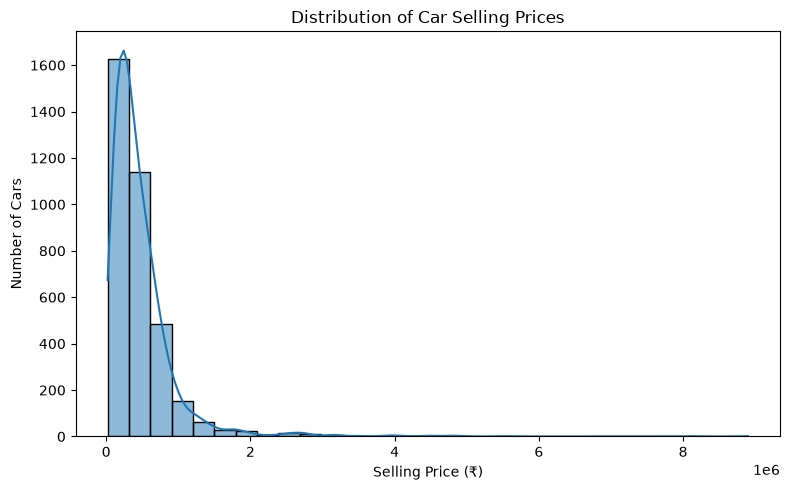

In [9]:
# Step 7.1: Distribution of selling prices

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=30,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

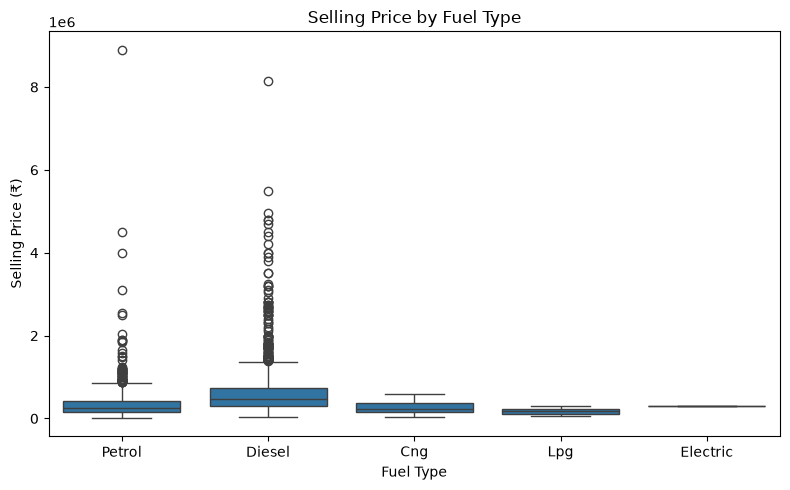

In [10]:
# Step 7.2: Selling price by fuel type

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="fuel",
    y="selling_price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

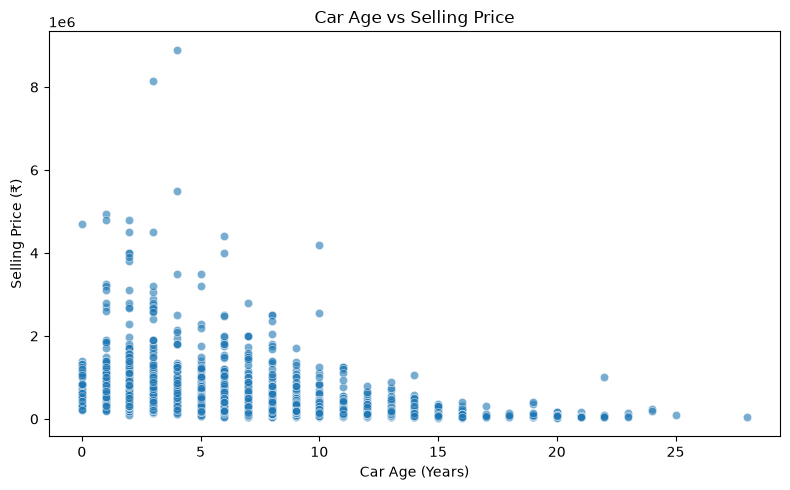

In [11]:
# Step 7.3: Car age vs selling price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.6
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

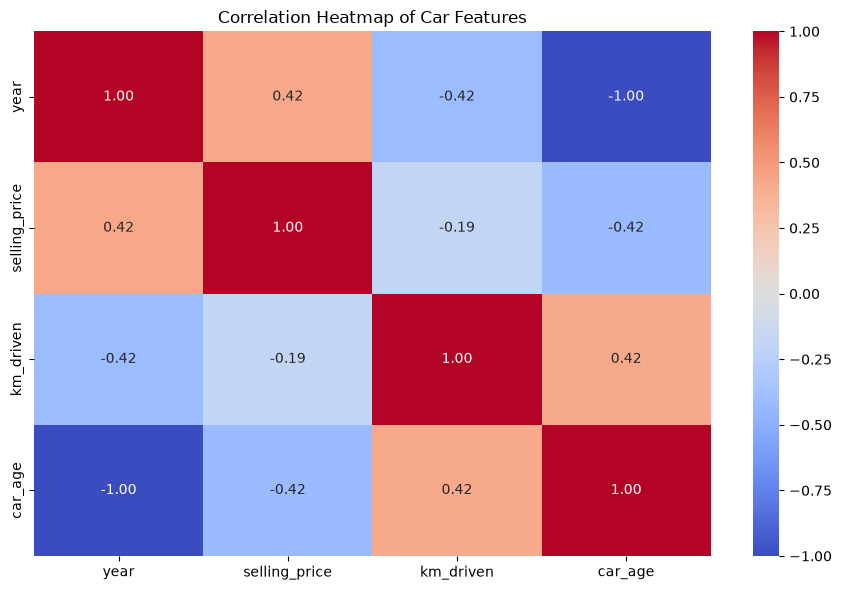

In [12]:
# Step 8: Feature Correlation Heatmap

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Car Features")
plt.tight_layout()
plt.show()

In [13]:
# Step 9: Prepare features and target

# Features used for prediction
X = df[
    [
        "car_age",
        "km_driven",
        "fuel",
        "seller_type",
        "transmission",
        "owner",
        "brand"
    ]
].copy()

# Target variable
y = df["selling_price"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (3577, 7)
Target shape: (3577,)


,car_age,km_driven,fuel,seller_type,transmission,owner,brand
0,13,70000,Petrol,Individual,Manual,First Owner,Maruti
1,13,50000,Petrol,Individual,Manual,First Owner,Maruti
2,8,100000,Diesel,Individual,Manual,First Owner,Hyundai
3,3,46000,Petrol,Individual,Manual,First Owner,Datsun
4,6,141000,Diesel,Individual,Manual,Second Owner,Honda


0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

In [14]:
# Step 10: Split data into training and testing sets

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2861
Testing rows: 716


In [15]:
# Step 11: Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical features
numeric_features = [
    "car_age",
    "km_driven"
]

# Categorical features
categorical_features = [
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "brand"
]

# Process numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
# Step 12: Train two regression models

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Model 2: Random Forest Regressor
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models
linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


In [17]:
# Step 13: Evaluate both models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():

    # Predict prices on test data
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,206368.40,431734.10,0.42
1,Random Forest,158905.93,367026.89,0.58


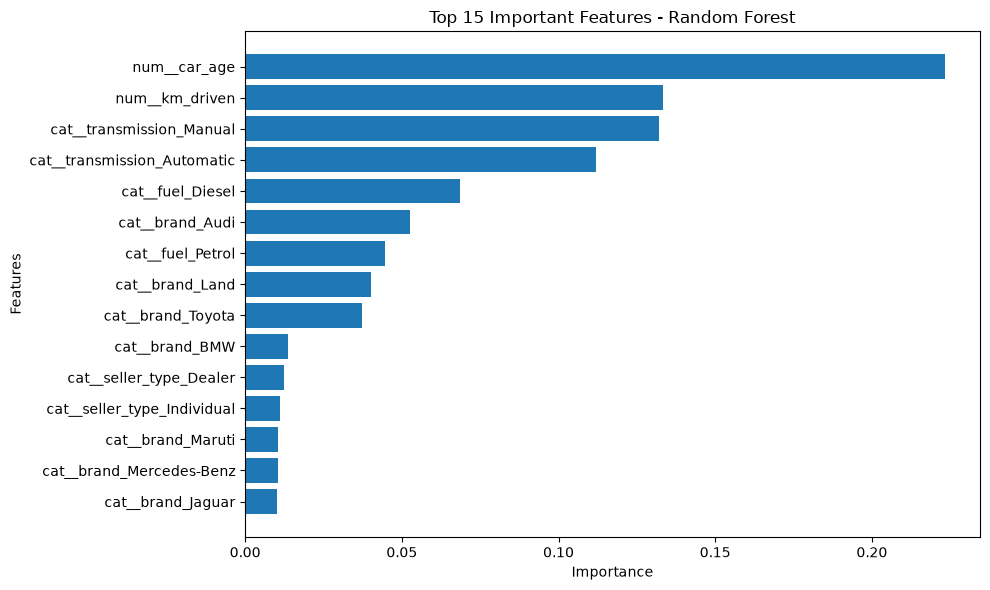

In [18]:
# Step 14: Feature Importance Chart

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest model
rf_model = random_forest_model.named_steps["model"]

# Get the feature names after preprocessing
feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance values
importance_values = rf_model.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [20]:
# Step 15: Predict the price of a sample car

sample_car = pd.DataFrame([{
    "car_age": 5,
    "km_driven": 50000,
    "fuel": "Petrol",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "brand": "Maruti"
}])

predicted_price = random_forest_model.predict(sample_car)

print(
    "Predicted Selling Price: ₹",
    round(predicted_price[0], 2)
)

Predicted Selling Price: ₹ 257540.99


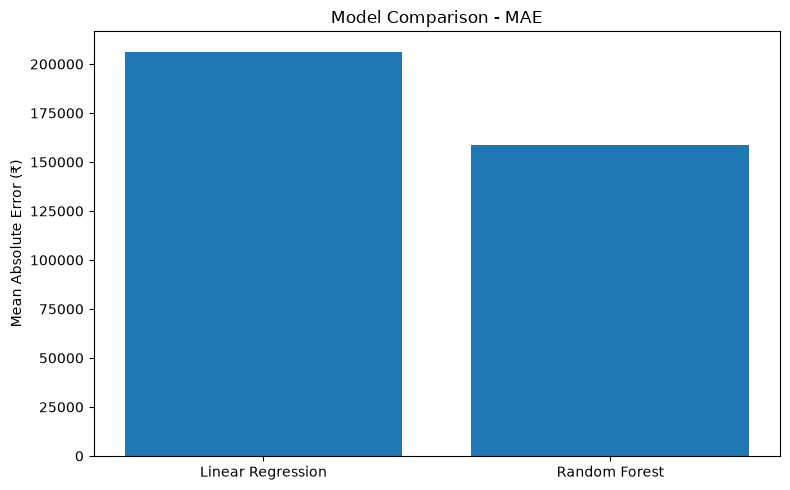

In [21]:
# Step 16: Compare model performance

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.ylabel("Mean Absolute Error (₹)")
plt.title("Model Comparison - MAE")
plt.tight_layout()
plt.show()

# Car Price Prediction Using Machine Learning

## Project Objective
The objective of this project is to predict the selling price of used cars using machine learning regression models.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## Dataset
Vehicle dataset from CarDekho.

## Data Preprocessing
- Checked missing values.
- Removed duplicate records.
- Standardized categorical values.
- Extracted car brand from the name.
- Calculated car age using the year column.
- Applied One-Hot Encoding to categorical features.

## Exploratory Data Analysis
Created visualizations for:
- Selling price distribution
- Selling price by fuel type
- Selling price versus car age
- Feature correlation heatmap

## Machine Learning Models
1. Linear Regression
2. Random Forest Regressor

## Model Evaluation

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 206368.40 | 431734.10 | 0.42 |
| Random Forest | 158905.93 | 367026.89 | 0.58 |

Random Forest performed better than Linear Regression on this test split because it achieved lower MAE and RMSE and a higher R² score.

## Conclusion
The project demonstrates how machine learning can be used to estimate used-car selling prices from vehicle features. Random Forest performed better than Linear Regression in this experiment. Model performance can be improved through further data cleaning, feature engineering and hyperparameter tuning.

The predictions are estimates and should not be treated as guaranteed market prices.